# Chapter 6: Geometric Transformation and Eigen Decomposition — Interactive Coding Project

**Companion Notebook for *Mathematics for AI and Machine Learning* ([math4ai.org](https://math4ai.org))**  
**Author**: Henry Fuheng Wu

This interactive notebook implements all **7 exercises** and spectral algorithms from **Chapter 6**, bridging analytical derivations with **NumPy**, **SciPy**, and **PyTorch**:

- **Part I — Eigenbases, RNN Matrix Powers, PCA & Hessian Spectrum (Exercises 1–4)**:
  - **Exercise 1**: Eigenvalues, repeated-eigenvalue eigenspace basis, and expanding $W\mathbf{x} = \sum_{i=1}^3 c_i \lambda_i \mathbf{v}_i$.
  - **Exercise 2**: Eigendecomposition $W = V\Lambda V^{-1}$, fast matrix powers $W^k = V\Lambda^k V^{-1}$ in RNNs, and exploding modes ($\lambda_1 = 2$).
  - **Exercise 3**: Orthogonal spectral decomposition $C = V\Lambda V^\top = \sum_i \lambda_i \mathbf{v}_i \mathbf{v}_i^\top$ and Principal Component Analysis (PCA) explained variance ratio.
  - **Exercise 4**: Computing $\operatorname{tr}(A) = \sum \lambda_i$, $\det(A) = \prod \lambda_i$, and Hessian positive definiteness / condition number from eigenvalues.
- **Part II — Dynamical Stability, Biorthogonality, Geometry & Matrix Exponentials (Exercises 5–7 + Deep Dive)**:
  - **Exercise 5**: Linear dynamical system $\mathbf{x}_{t+1} = A\mathbf{x}_t$, $A^{10}$, marginal stability, and the Markov stationary limit $\lim_{t\to\infty} A^t = \mathbf{v}_2 \mathbf{p}_2^\top$.
  - **Exercise 6**: Left eigenvectors $P = (V^{-1})^\top$, biorthogonality $P^\top V = I$, rank-1 spectral expansion $A = \sum_n \lambda_n \mathbf{v}_n \mathbf{p}_n^\top$, and non-symmetric deflation.
  - **Exercise 7**: Geometric transformations $M_1, M_2, M_3, M_4$ on grids and unit circles, area scaling $|\det M|$, orthogonality $M^\top M = I$, and complex rotation eigenvalues $e^{\pm i\theta}$.
  - **Deep Dive**: Power method with rank-1 deflation, matrix exponential $e^{tA}$ (`scipy.linalg.expm`), Jacobi's identity $\det(e^M) = e^{\operatorname{tr}(M)}$, linear ODE trajectories, and the Cayley–Hamilton theorem.

- **Part III — Numerical Spectral Analysis & Graph Learning (Labs 8–11)**:
  - **Lab 8 — Dynamic Mode Decomposition (DMD)**: Recovering spatio-temporal coherent modes, growth/decay rates, and oscillation frequencies from snapshot matrices.
  - **Lab 9 — Circulant Matrices & FFT Diagonalization**: Proving that the DFT diagonalizes all circulant matrices, accelerating circular convolution from (N^2)$ to (N \log N)$.
  - **Lab 10 — Ill-Conditioned Eigenvectors & Non-Normal Transient Growth**: High pseudospectral sensitivity in nearly defective matrices and severe transient amplification in non-normal RNNs.
  - **Lab 11 — Graph Convolutions as Spectral Low-Pass Filters**: Graph Fourier transform via normalized Laplacian eigenvectors, demonstrating noise attenuation via heat-kernel filters.


In [1]:
import numpy as np
import scipy.linalg as la
import torch
import os
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
torch.set_printoptions(precision=4, sci_mode=False)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
print(f"NumPy {np.__version__} | PyTorch {torch.__version__}")

def save_fig(name, **kw):
    # Writes the figure premium.md shows; skipped when ../img is absent (e.g. on Colab).
    if os.path.isdir("../img"):
        plt.savefig(f"../img/{name}", **kw)

NumPy 2.4.6 | PyTorch 2.10.0+cu128


---
## Part I: Eigenbases, RNN Matrix Powers, PCA & Hessian Spectrum (Exercises 1–4)

### Exercise 1: Eigenvalues and Eigenvectors in Linear Transformations

Given the $3\times 3$ weight matrix:
$$W = \begin{bmatrix} 2 & -1 & 1 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$
1. Compute all eigenvalues of $W$ (with multiplicities) from $\det(W - \lambda I) = 0$.
2. Find a corresponding eigenvector basis for each eigenvalue.
3. Verify $W\mathbf{v}_i = \lambda_i \mathbf{v}_i$ for $i = 1, 2, 3$.
4. Expand $\mathbf{x} = [1, 1, 1]^\top = \sum_{i=1}^3 c_i \mathbf{v}_i$ and verify $W\mathbf{x} = \sum_{i=1}^3 c_i \lambda_i \mathbf{v}_i$.


In [2]:
# Exercise 1: Eigenvalues, Eigenspaces & Eigenbasis Expansion
W = np.array([[2., -1., 1.],
              [0.,  1., 0.],
              [0.,  0., 1.]])

# Task 1: Upper triangular diagonal entries give eigenvalues {2, 1, 1}
lams = np.array([2., 1., 1.])
print("Task 1 — Eigenvalues of W:", np.linalg.eigvals(W))

# Task 2: Eigenvector for lam=2 and 2D eigenspace basis for lam=1
v1 = np.array([ 1., 0., 0.])
v2 = np.array([ 1., 1., 0.])
v3 = np.array([-1., 0., 1.])
ns_lam1 = la.null_space(W - 1.0 * np.eye(3))
print(f"Task 2 — dim N(W - I) = {ns_lam1.shape[1]} (equals algebraic multiplicity 2)")

# Task 3: Verify W v_i = lam_i v_i
for idx, (lam, v) in enumerate(zip(lams, [v1, v2, v3]), 1):
    assert np.allclose(W @ v, lam * v)
    print(f"Task 3 — Pair {idx} (lam={lam:.0f}): W @ v == {lam:.0f} * v -> True")

# Task 4: Expand x = [1, 1, 1]^T in the eigenbasis V = [v1, v2, v3]
V = np.column_stack([v1, v2, v3])
x = np.array([1., 1., 1.])
c = np.linalg.solve(V, x)
Wx_modes = sum(c[i] * lams[i] * V[:, i] for i in range(3))
Wx_direct = W @ x
print(f"\nTask 4 — Eigenbasis coordinates c = {c}")
print(f"Task 4 — Mode expansion sum_i c_i lam_i v_i = {Wx_modes} | Direct W @ x = {Wx_direct}")
assert np.allclose(Wx_modes, Wx_direct)


Task 1 — Eigenvalues of W: [2. 1. 1.]
Task 2 — dim N(W - I) = 2 (equals algebraic multiplicity 2)
Task 3 — Pair 1 (lam=2): W @ v == 2 * v -> True
Task 3 — Pair 2 (lam=1): W @ v == 1 * v -> True
Task 3 — Pair 3 (lam=1): W @ v == 1 * v -> True

Task 4 — Eigenbasis coordinates c = [1. 1. 1.]
Task 4 — Mode expansion sum_i c_i lam_i v_i = [2. 1. 1.] | Direct W @ x = [2. 1. 1.]


---
### Exercise 2: Eigen Decomposition and Matrix Powers in Recurrent Networks

For the same weight matrix $W$:
1. Construct $V = [\mathbf{v}_1, \mathbf{v}_2, \mathbf{v}_3]$ and $\Lambda = \operatorname{diag}(2, 1, 1)$.
2. Compute $V^{-1}$ and verify $W = V\Lambda V^{-1}$.
3. Compute $W^3 = V\Lambda^3 V^{-1}$ and verify against direct multiplication $W^3$.
4. Analyze $\lim_{k\to\infty} W^k$ via the closed-form expression $W^k = V\Lambda^k V^{-1}$.


In [3]:
# Exercise 2: Eigendecomposition & Matrix Powers in RNNs
V_inv = np.linalg.inv(V)
Lambda = np.diag(lams)

print("Tasks 1–3 — V^-1:\n", V_inv.astype(int))
print("Verify V @ Lambda @ V^-1 == W:", np.allclose(V @ Lambda @ V_inv, W))

# Task 4: Compute W^3 via V @ Lambda^3 @ V^-1
W3_eig = V @ np.diag(lams ** 3) @ V_inv
W3_direct = np.linalg.matrix_power(W, 3)
print("\nTask 4 — W^3 via eigendecomposition:\n", W3_eig.astype(int))
print("Matches W @ W @ W:", np.allclose(W3_eig, W3_direct))

# Task 5: Asymptotic divergence as k -> infinity because lam_1 = 2 > 1
print("\nTask 5 — Growth of W^k across recurrent steps k:")
for k in [1, 2, 3, 5, 10]:
    Wk = V @ np.diag(lams ** k) @ V_inv
    formula_row0 = np.array([2**k, -(2**k - 1), 2**k - 1])
    assert np.allclose(Wk[0], formula_row0)
    print(f"  k={k:>2}: first row = {Wk[0].astype(int)} | ||W^k||_F = {np.linalg.norm(Wk):.2f}")


Tasks 1–3 — V^-1:
 [[ 1 -1  1]
 [ 0  1  0]
 [ 0  0  1]]
Verify V @ Lambda @ V^-1 == W: True

Task 4 — W^3 via eigendecomposition:
 [[ 8 -7  7]
 [ 0  1  0]
 [ 0  0  1]]
Matches W @ W @ W: True

Task 5 — Growth of W^k across recurrent steps k:
  k= 1: first row = [ 2 -1  1] | ||W^k||_F = 2.83
  k= 2: first row = [ 4 -3  3] | ||W^k||_F = 6.00
  k= 3: first row = [ 8 -7  7] | ||W^k||_F = 12.81
  k= 5: first row = [ 32 -31  31] | ||W^k||_F = 54.30
  k=10: first row = [ 1024 -1023  1023] | ||W^k||_F = 1772.47


---
### Exercise 3: Spectral Decomposition and Principal Component Analysis (PCA)

Given the $2\times 2$ covariance matrix:
$$C = \begin{bmatrix} 5 & 2 \\ 2 & 2 \end{bmatrix}$$
1. Compute the eigenvalues $\lambda_1, \lambda_2$ and normalized unit eigenvectors $\mathbf{v}_1, \mathbf{v}_2$ of $C$.
2. Verify $C = V\Lambda V^\top$ with orthogonal $V$.
3. Verify the rank-1 spectral sum $C = \lambda_1 \mathbf{v}_1 \mathbf{v}_1^\top + \lambda_2 \mathbf{v}_2 \mathbf{v}_2^\top$.
4. Compute the fraction of total variance $\operatorname{tr}(C) = 7$ captured by the first principal component ($6/7 \approx 85.71\%$).


Task 1 — Eigenvalues of C: [1. 6.]
Task 1 — Unit eigenvectors V * sqrt(5):
 [[ 1. -2.]
 [-2. -1.]]
Task 2 — V^T V == I and V @ Lambda @ V^T == C -> True
Task 3 — Rank-1 sum lam_1 v1 v1^T + lam_2 v2 v2^T == C -> True
Task 4 — PC1 variance: 85.71% (6/7) | PC2 variance: 14.29% (1/7)


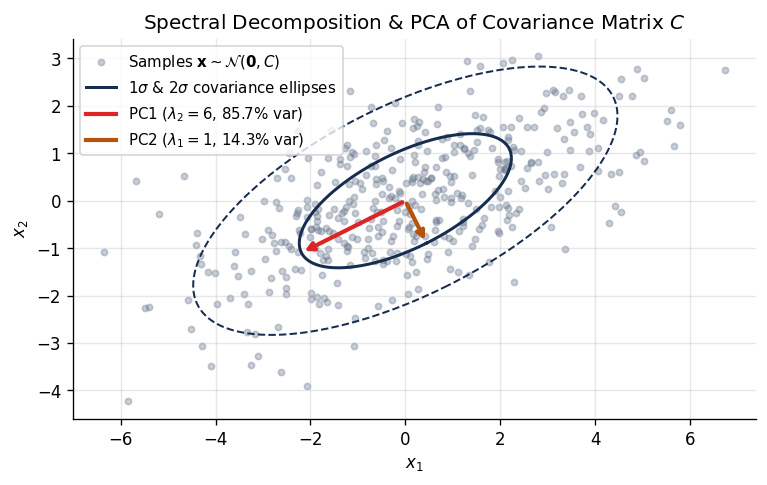

In [4]:
# Exercise 3: Spectral Decomposition & PCA on Covariance Matrix C
C = np.array([[5., 2.],
              [2., 2.]])

# Task 1: Orthonormal eigenpairs via eigh (ascending order: lam_1 = 1, lam_2 = 6)
lam_c, V_c = np.linalg.eigh(C)
print("Task 1 — Eigenvalues of C:", lam_c)
print("Task 1 — Unit eigenvectors V * sqrt(5):\n", np.round(V_c * np.sqrt(5), 4))

# Task 2: Verify orthogonality V^T V = I and C = V Lambda V^T
assert np.allclose(V_c.T @ V_c, np.eye(2)) and np.allclose(V_c @ np.diag(lam_c) @ V_c.T, C)
print("Task 2 — V^T V == I and V @ Lambda @ V^T == C -> True")

# Task 3: Rank-1 spectral sum
v1_c, v2_c = V_c[:, 0], V_c[:, 1]
C_rank1_sum = lam_c[0] * np.outer(v1_c, v1_c) + lam_c[1] * np.outer(v2_c, v2_c)
assert np.allclose(C_rank1_sum, C)
print("Task 3 — Rank-1 sum lam_1 v1 v1^T + lam_2 v2 v2^T == C -> True")

# Task 4: Explained variance ratio & visualization
var_ratios = lam_c[::-1] / np.trace(C)
print(f"Task 4 — PC1 variance: {var_ratios[0]*100:.2f}% (6/7) | PC2 variance: {var_ratios[1]*100:.2f}% (1/7)")

rng = np.random.default_rng(42)
X_pca = rng.multivariate_normal(mean=[0., 0.], cov=C, size=400)
theta_grid = np.linspace(0, 2 * np.pi, 200)
circle = np.vstack([np.cos(theta_grid), np.sin(theta_grid)])
ellipse_1std = V_c @ np.diag(np.sqrt(lam_c)) @ circle
ellipse_2std = 2.0 * ellipse_1std

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(X_pca[:, 0], X_pca[:, 1], s=14, alpha=0.35, color="#64748b", label=r"Samples $\mathbf{x} \sim \mathcal{N}(\mathbf{0}, C)$")
ax.plot(ellipse_1std[0], ellipse_1std[1], color="#162d50", lw=1.8, label=r"$1\sigma$ & $2\sigma$ covariance ellipses")
ax.plot(ellipse_2std[0], ellipse_2std[1], color="#162d50", lw=1.2, ls="--")
pc1_vec = np.sqrt(lam_c[1]) * v2_c
pc2_vec = np.sqrt(lam_c[0]) * v1_c
ax.annotate("", xy=pc1_vec, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#dc2626", lw=2.5))
ax.annotate("", xy=pc2_vec, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#b45309", lw=2.5))
ax.plot([], [], color="#dc2626", lw=2.5, label=rf"PC1 ($\lambda_2=6$, {var_ratios[0]*100:.1f}% var)")
ax.plot([], [], color="#b45309", lw=2.5, label=rf"PC2 ($\lambda_1=1$, {var_ratios[1]*100:.1f}% var)")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Spectral Decomposition & PCA of Covariance Matrix $C$")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
### Exercise 4: Trace and Determinant from Eigenvalues

Given the symmetric tridiagonal matrix:
$$A = \begin{bmatrix} 3 & 1 & 0 \\ 1 & 3 & 1 \\ 0 & 1 & 3 \end{bmatrix}$$
1. Compute the eigenvalues $\lambda_1, \lambda_2, \lambda_3 = 3 - \sqrt{2}, 3, 3 + \sqrt{2}$.
2. Verify $\operatorname{tr}(A) = \lambda_1 + \lambda_2 + \lambda_3 = 9$.
3. Verify $\det(A) = \lambda_1 \lambda_2 \lambda_3 = 21$.
4. Interpret $A$ as a positive-definite Hessian matrix with condition number $\kappa(A) = (3+\sqrt{2})/(3-\sqrt{2}) \approx 2.78$.


In [5]:
# Exercise 4: Trace, Determinant & Curvature from Eigenvalues
A4 = np.array([[3., 1., 0.],
               [1., 3., 1.],
               [0., 1., 3.]])

lam4 = np.linalg.eigvalsh(A4)
lam4_exact = np.array([3. - np.sqrt(2), 3., 3. + np.sqrt(2)])
print("Task 1 — Eigenvalues of A:", np.round(lam4, 4))
assert np.allclose(lam4, lam4_exact)

print(f"Task 2 — tr(A) = {np.trace(A4):.1f} == sum(lam) = {np.sum(lam4):.1f}")
print(f"Task 3 — det(A) = {np.linalg.det(A4):.1f} == prod(lam) = {np.prod(lam4):.1f}")
assert np.isclose(np.trace(A4), np.sum(lam4)) and np.isclose(np.linalg.det(A4), np.prod(lam4))

kappa_A4 = lam4[-1] / lam4[0]
print(f"Task 4 — All eigenvalues > 0 (SPD local minimum): {np.all(lam4 > 0)} | kappa(A) = {kappa_A4:.4f}")


Task 1 — Eigenvalues of A: [1.5858 3.     4.4142]
Task 2 — tr(A) = 9.0 == sum(lam) = 9.0
Task 3 — det(A) = 21.0 == prod(lam) = 21.0
Task 4 — All eigenvalues > 0 (SPD local minimum): True | kappa(A) = 2.7836


---
## Part II: Dynamical Stability, Biorthogonality, Geometry & Matrix Exponentials (Exercises 5–7)

### Exercise 5: Matrix Powers and Stability in Dynamical Systems

Given the linear dynamical system $\mathbf{x}_{t+1} = A\mathbf{x}_t$ with transition matrix:
$$A = \begin{bmatrix} 0.8 & 0.2 \\ 0.1 & 0.9 \end{bmatrix}$$
1. Compute the eigenvalues $\lambda_1 = 0.7, \lambda_2 = 1.0$.
2. Find the eigendecomposition $A = V\Lambda V^{-1}$ with $V = \begin{bmatrix} -2 & 1 \\ 1 & 1 \end{bmatrix}$.
3. Compute $A^{10} = V\Lambda^{10}V^{-1}$ and the stationary limit $\lim_{t\to\infty} A^t = \mathbf{v}_2\mathbf{p}_2^\top = \begin{bmatrix} 1/3 & 2/3 \\ 1/3 & 2/3 \end{bmatrix}$.
4. Show that $\mathbf{x}_0 = [1, 1]^\top$ is a fixed point ($\mathbf{x}_t = [1, 1]^\top$ for all $t$), while general initial states $\mathbf{x}_0$ converge along the $\mathbf{v}_1 = [-2, 1]^\top$ direction onto the fixed-point line $\operatorname{span}(\mathbf{v}_2)$.


Tasks 1–2 — V^-1 * 3:
 [[-1.  1.]
 [ 1.  2.]]

Task 3 — A^10:
 [[0.3522 0.6478]
 [0.3239 0.6761]]
Task 4 — Stationary limit lim_{t->inf} A^t = v2 p2^T:
 [[0.3333 0.6667]
 [0.3333 0.6667]]

Task 5 — For x0 = [1, 1]^T, eigen-coordinates c = [-0.  1.], x_3 = [1. 1.]


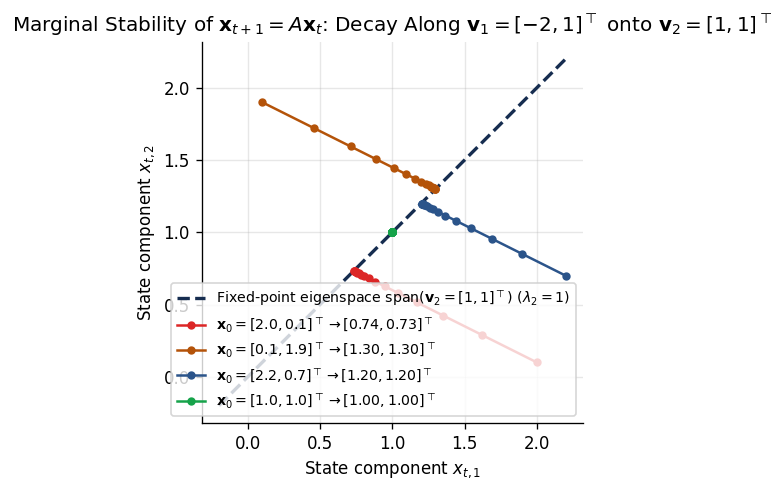

In [6]:
# Exercise 5: Dynamical System x_{t+1} = A x_t, A^10 & Marginal Stability
A5 = np.array([[0.8, 0.2],
               [0.1, 0.9]])
V5 = np.array([[-2., 1.],
               [ 1., 1.]])
lam5 = np.array([0.7, 1.0])
V5_inv = np.linalg.inv(V5)

print("Tasks 1–2 — V^-1 * 3:\n", np.round(V5_inv * 3, 2))
assert np.allclose(V5 @ np.diag(lam5) @ V5_inv, A5)

A5_10 = V5 @ np.diag(lam5 ** 10) @ V5_inv
A5_inf = np.outer(V5[:, 1], V5_inv[1, :])
print("\nTask 3 — A^10:\n", np.round(A5_10, 4))
print("Task 4 — Stationary limit lim_{t->inf} A^t = v2 p2^T:\n", np.round(A5_inf, 4))
assert np.allclose(A5_10, np.linalg.matrix_power(A5, 10))
assert np.allclose(A5_inf, np.linalg.matrix_power(A5, 200))

# Task 5: Trajectory from x0 = [1, 1]^T and from general initial states
x0_fixed = np.array([1., 1.])
c_fixed = V5_inv @ x0_fixed
print(f"\nTask 5 — For x0 = [1, 1]^T, eigen-coordinates c = {c_fixed}, x_3 = {V5 @ ((lam5**3)*c_fixed)}")

fig, ax = plt.subplots(figsize=(6.8, 4.2))
s_line = np.linspace(-0.2, 2.2, 100)
ax.plot(s_line, s_line, "--", color="#162d50", lw=2.0, label=r"Fixed-point eigenspace $\operatorname{span}(\mathbf{v}_2 = [1, 1]^\top)$ ($\lambda_2=1$)")

init_states = [np.array([2.0, 0.1]), np.array([0.1, 1.9]), np.array([2.2, 0.7]), np.array([1.0, 1.0])]
colors = ["#dc2626", "#b45309", "#2b548a", "#16a34a"]
for x_init, col in zip(init_states, colors):
    traj = np.array([V5 @ ((lam5 ** t) * (V5_inv @ x_init)) for t in range(18)])
    ax.plot(traj[:, 0], traj[:, 1], "o-", color=col, ms=4, lw=1.5,
            label=rf"$\mathbf{{x}}_0 = [{x_init[0]:.1f}, {x_init[1]:.1f}]^\top \to [{traj[-1,0]:.2f}, {traj[-1,1]:.2f}]^\top$")

ax.set_xlabel("State component $x_{t,1}$")
ax.set_ylabel("State component $x_{t,2}$")
ax.set_title(r"Marginal Stability of $\mathbf{x}_{t+1} = A\mathbf{x}_t$: Decay Along $\mathbf{v}_1 = [-2, 1]^\top$ onto $\mathbf{v}_2 = [1, 1]^\top$")
ax.set_aspect("equal")
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
### Exercise 6: Left Eigenvectors and Biorthogonality

For the non-symmetric matrix:
$$A = \begin{bmatrix} 2 & 1 \\ 0 & 3 \end{bmatrix}$$
1. Construct $V = [\mathbf{v}_1, \mathbf{v}_2] = \begin{bmatrix} 1 & 1 \\ 0 & 1 \end{bmatrix}$ and $\Lambda = \operatorname{diag}(2, 3)$.
2. Compute $V^{-1} = \begin{bmatrix} 1 & -1 \\ 0 & 1 \end{bmatrix}$ and verify $A = V\Lambda V^{-1}$.
3. Compute $P = (V^{-1})^\top = [\mathbf{p}_1, \mathbf{p}_2]$ and verify $A^\top \mathbf{p}_n = \lambda_n \mathbf{p}_n$.
4. Verify biorthogonality $\mathbf{p}_i^\top \mathbf{v}_j = \delta_{ij}$ ($P^\top V = I_2$).
5. Verify the spectral expansion $A = \lambda_1 \mathbf{v}_1 \mathbf{p}_1^\top + \lambda_2 \mathbf{v}_2 \mathbf{p}_2^\top$.


In [7]:
# Exercise 6: Left Eigenvectors, Biorthogonality & Spectral Sum
A6 = np.array([[2., 1.],
               [0., 3.]])
lam6 = np.array([2., 3.])
V6 = np.array([[1., 1.],
               [0., 1.]])
V6_inv = np.linalg.inv(V6)
P6 = V6_inv.T

print("Tasks 1–2 — V:\n", V6, "\nV^-1:\n", V6_inv)
assert np.allclose(V6 @ np.diag(lam6) @ V6_inv, A6)

print("\nTask 3 — Left eigenvector matrix P = (V^-1)^T:\n", P6)
print("Verify A^T P == P @ diag(lam):", np.allclose(A6.T @ P6, P6 @ np.diag(lam6)))

print("\nTask 4 — Biorthogonality P^T @ V:\n", P6.T @ V6)
assert np.allclose(P6.T @ V6, np.eye(2))

term1_6 = lam6[0] * np.outer(V6[:, 0], P6[:, 0])
term2_6 = lam6[1] * np.outer(V6[:, 1], P6[:, 1])
print("\nTask 5 — Rank-1 pieces:")
print("  lam_1 v1 p1^T:\n", term1_6)
print("  lam_2 v2 p2^T:\n", term2_6)
print("  Sum == A:", np.allclose(term1_6 + term2_6, A6))


Tasks 1–2 — V:
 [[1. 1.]
 [0. 1.]] 
V^-1:
 [[ 1. -1.]
 [ 0.  1.]]

Task 3 — Left eigenvector matrix P = (V^-1)^T:
 [[ 1.  0.]
 [-1.  1.]]
Verify A^T P == P @ diag(lam): True

Task 4 — Biorthogonality P^T @ V:
 [[1. 0.]
 [0. 1.]]

Task 5 — Rank-1 pieces:
  lam_1 v1 p1^T:
 [[ 2. -2.]
 [ 0. -0.]]
  lam_2 v2 p2^T:
 [[0. 3.]
 [0. 3.]]
  Sum == A: True


---
### Exercise 7: Matching Linear Transformations with Matrices

Consider the four $2\times 2$ transformation matrices:
$$M_1 = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}, \quad M_2 = \begin{bmatrix} 1.5 & 1.0 \\ 0.1 & 0.5 \end{bmatrix}, \quad M_3 = \begin{bmatrix} 2 & 0 \\ 0 & 1 \end{bmatrix}, \quad M_4 = \begin{bmatrix} \frac{\sqrt{2}}{2} & -\frac{\sqrt{2}}{2} \\ \frac{\sqrt{2}}{2} & \frac{\sqrt{2}}{2} \end{bmatrix}$$
1. Visualize how $M_1, M_2, M_3, M_4$ transform a square grid and the unit circle, matching plots (a)–(d).
2. Compute eigenvalues, area scaling $|\det M|$, and orthogonality $M^\top M = I$.
3. Verify that $M_4$ has complex conjugate eigenvalues $e^{\pm i\pi/4}$, $M_3$ maps the unit circle to an ellipse of area $2\pi$, and $M_2$ has eigenvalues $\frac{\operatorname{tr}(M_2) \pm \sqrt{\operatorname{tr}(M_2)^2 - 4\det(M_2)}}{2} \approx 1.5916, 0.4084$.


(a) M1: Identity             | det= 1.00 | orth=True  | eigs=[1. 1.]
(b) M2: Scale + Shear        | det= 0.65 | orth=False | eigs=[1.5916 0.4084]
(c) M3: Horizontal Stretch   | det= 2.00 | orth=False | eigs=[2. 1.]
(d) M4: 45° Rotation         | det= 1.00 | orth=True  | eigs=[0.7071+0.7071j 0.7071-0.7071j]


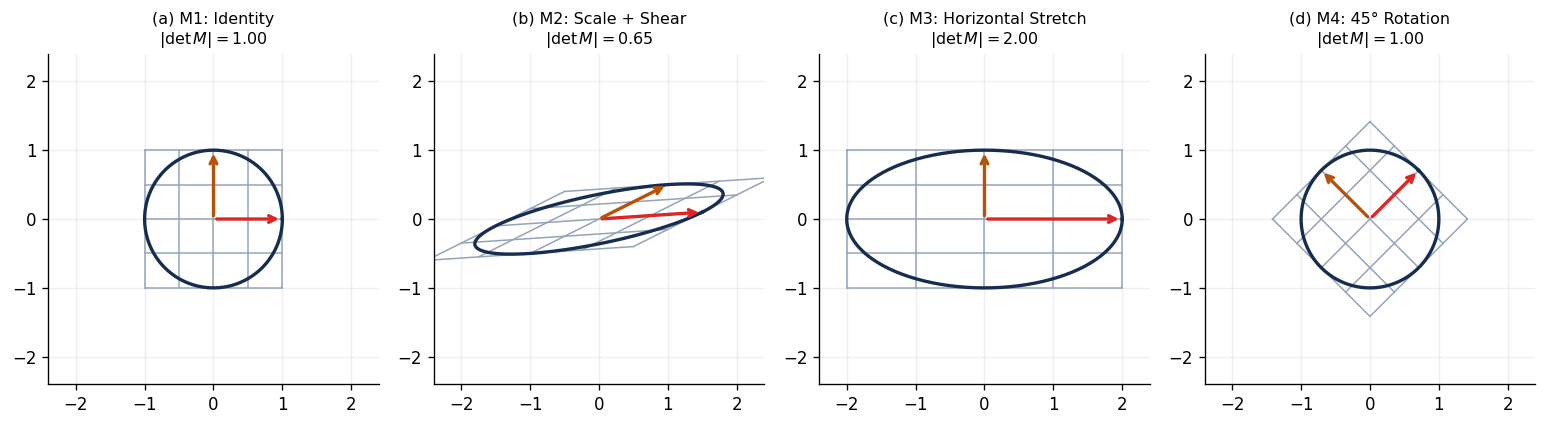

In [8]:
# Exercise 7: Geometric Transformations on Grids & Unit Circles
s = np.sqrt(2) / 2
M1 = np.eye(2)
M2 = np.array([[1.5, 1.0], [0.1, 0.5]])
M3 = np.array([[2.0, 0.0], [0.0, 1.0]])
M4 = np.array([[s, -s], [s, s]])
matrices = [("(a) M1: Identity", M1),
            ("(b) M2: Scale + Shear", M2),
            ("(c) M3: Horizontal Stretch", M3),
            ("(d) M4: 45° Rotation", M4)]

for title, M in matrices:
    eigs = np.linalg.eigvals(M)
    det_m = np.linalg.det(M)
    is_orth = np.allclose(M.T @ M, np.eye(2))
    print(f"{title:<28} | det={det_m:5.2f} | orth={str(is_orth):<5} | eigs={np.round(eigs, 4)}")

# Visualize all 4 transformations on [-1, 1]^2 grid + unit circle
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
grid_vals = np.linspace(-1, 1, 5)
t_line = np.linspace(-1, 1, 50)
ang = np.linspace(0, 2 * np.pi, 200)
unit_circ = np.vstack([np.cos(ang), np.sin(ang)])

for ax, (title, M) in zip(axes, matrices):
    for g in grid_vals:
        h_seg = M @ np.vstack([t_line, np.full_like(t_line, g)])
        v_seg = M @ np.vstack([np.full_like(t_line, g), t_line])
        ax.plot(h_seg[0], h_seg[1], color="#94a3b8", lw=0.9)
        ax.plot(v_seg[0], v_seg[1], color="#94a3b8", lw=0.9)
    trans_circ = M @ unit_circ
    ax.plot(trans_circ[0], trans_circ[1], color="#162d50", lw=2.0)
    e1_img, e2_img = M[:, 0], M[:, 1]
    ax.annotate("", xy=e1_img, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#dc2626", lw=2.0))
    ax.annotate("", xy=e2_img, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#b45309", lw=2.0))
    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-2.4, 2.4)
    ax.set_aspect("equal")
    ax.set_title(f"{title}\n$|\\det M| = {abs(np.linalg.det(M)):.2f}$", fontsize=9.5)
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


---
## Deep Dive: Power Method with Deflation, Matrix Exponential $e^{tA}$ & Cayley–Hamilton

1. **Power Method with Rank-1 Deflation**: Iterating $\mathbf{v}^{(k+1)} = M\mathbf{v}^{(k)} / \|M\mathbf{v}^{(k)}\|_2$ converges at rate $|\lambda_2/\lambda_1|^k$ to the dominant eigenpair; subtracting $\lambda_1 \mathbf{v}_1 \mathbf{v}_1^\top$ reveals the next eigenpair.
2. **Matrix Exponential & Continuous-Time ODEs**: $\mathbf{x}(t) = e^{tA}\mathbf{x}_0$ solves $\dot{\mathbf{x}}(t) = A\mathbf{x}(t)$, and $\det(e^M) = e^{\operatorname{tr}(M)}$.
3. **Cayley–Hamilton Theorem**: Every square matrix satisfies its own characteristic polynomial $p(M) = 0$.


expm(K) == M4 (45° rotation): True
det(expm(M)) == exp(tr(M))  : True
Cayley-Hamilton ||p(M)||_F  : 6.28e-16


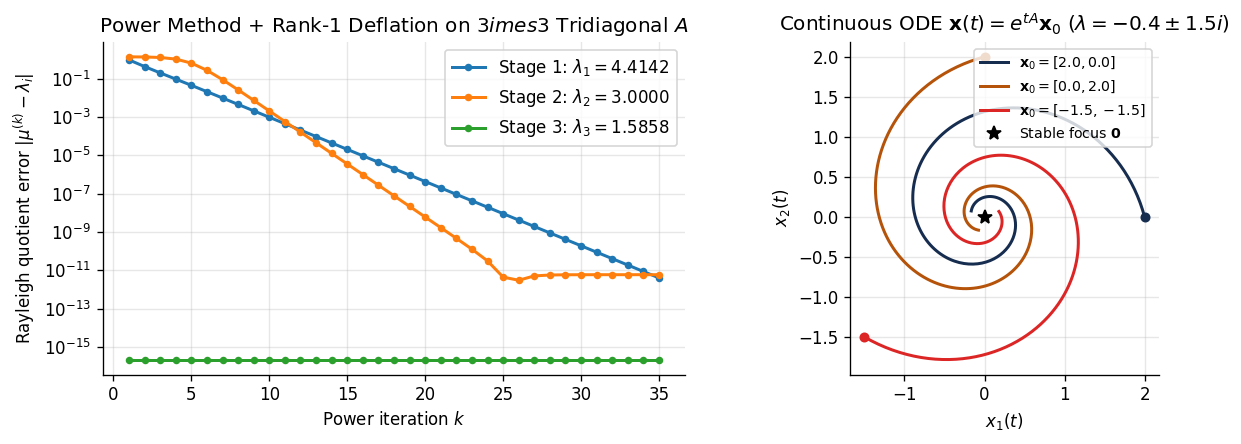

In [9]:
# Deep Dive: Power Method Deflation Convergence, Matrix Exponential & Cayley-Hamilton
def power_method_trace(M, exact_lam, iters=35, seed=0):
    v = np.random.default_rng(seed).standard_normal(M.shape[0])
    v /= np.linalg.norm(v)
    errs = []
    for _ in range(iters):
        v = M @ v
        v /= np.linalg.norm(v)
        mu = float(v @ M @ v)
        errs.append(max(abs(mu - exact_lam), 1e-16))
    return mu, v, errs

# 1. Deflate all 3 eigenvalues of A4 from Exercise 4
B_work = A4.copy()
exact_desc = [3. + np.sqrt(2), 3., 3. - np.sqrt(2)]
histories = []
for step, target_lam in enumerate(exact_desc):
    mu, v, errs = power_method_trace(B_work, target_lam, iters=35, seed=step)
    histories.append((step + 1, target_lam, errs))
    B_work = B_work - mu * np.outer(v, v)

# 2. Matrix exponential & Cayley-Hamilton checks
theta = np.pi / 4
K = np.array([[0., -theta], [theta, 0.]])
M_test = np.array([[1., 2.], [3., 4.]])
print("expm(K) == M4 (45° rotation):", np.allclose(la.expm(K), M4))
print("det(expm(M)) == exp(tr(M))  :", np.isclose(np.linalg.det(la.expm(M_test)), np.exp(np.trace(M_test))))
p_M = M_test @ M_test - np.trace(M_test) * M_test + np.linalg.det(M_test) * np.eye(2)
print("Cayley-Hamilton ||p(M)||_F  :", f"{np.linalg.norm(p_M):.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for idx, target_lam, errs in histories:
    axes[0].semilogy(range(1, len(errs) + 1), errs, "o-", ms=3.5, lw=1.8,
                     label=rf"Stage {idx}: $\lambda_{idx} = {target_lam:.4f}$")
axes[0].set_xlabel("Power iteration $k$")
axes[0].set_ylabel(r"Rayleigh quotient error $|\mu^{(k)} - \lambda_i|$")
axes[0].set_title("Power Method + Rank-1 Deflation on $3\times 3$ Tridiagonal $A$")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Continuous-time ODE trajectories x(t) = expm(t * A_ode) x0 for spiral sink
A_spiral = np.array([[-0.4, -1.5], [1.5, -0.4]])
t_vals = np.linspace(0, 6.0, 200)
for x0_sp, col in [([2.0, 0.0], "#162d50"), ([0.0, 2.0], "#b45309"), ([-1.5, -1.5], "#dc2626")]:
    traj_sp = np.array([la.expm(t * A_spiral) @ np.array(x0_sp) for t in t_vals])
    axes[1].plot(traj_sp[:, 0], traj_sp[:, 1], lw=1.8, color=col, label=rf"$\mathbf{{x}}_0 = {x0_sp}$")
    axes[1].plot(x0_sp[0], x0_sp[1], "o", color=col, ms=5)
axes[1].plot(0, 0, "k*", ms=9, label=r"Stable focus $\mathbf{0}$")
axes[1].set_aspect("equal")
axes[1].set_xlabel("$x_1(t)$")
axes[1].set_ylabel("$x_2(t)$")
axes[1].set_title(r"Continuous ODE $\mathbf{x}(t) = e^{tA}\mathbf{x}_0$ ($\lambda = -0.4 \pm 1.5i$)")
axes[1].legend(fontsize=8.5)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Part 8: Dynamic Mode Decomposition (DMD) & Spatio-Temporal Systems

Dynamic Mode Decomposition (DMD) fits a best-fit linear operator $\mathbf{x}_{t+1} pprox A \mathbf{x}_t$ to snapshot matrices  = [\mathbf{x}_0, \dots, \mathbf{x}_{m-1}]$ and  = [\mathbf{x}_1, \dots, \mathbf{x}_m]$.
By truncating the SVD of  = U \Sigma V^*$, DMD computes the low-dimensional projection $	ilde{A} = U_r^* X_2 V_r \Sigma_r^{-1}$ and extracts:
1. **Dynamic Modes**: $oldsymbol\Phi = X_2 V_r \Sigma_r^{-1} W$, where $ contains eigenvectors of $	ilde{A}$.
2. **Continuous Frequencies & Growth Rates**: $\omega_j = \ln(\lambda_j) / \Delta t$, isolating oscillation frequencies $\operatorname{Im}(\omega_j)/(2\pi)$ and decay rates $\operatorname{Re}(\omega_j)$.

In [ ]:
import os
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Generate Spatio-Temporal Multi-Frequency Signal
t = np.linspace(0, 10, 200)
dt = t[1] - t[0]
x_space = np.linspace(-5, 5, 80)

phi1 = np.exp(-0.5 * (x_space / 1.5)**2)[:, None]
phi2 = np.sin(x_space)[:, None] * np.exp(-0.3 * (x_space / 2.0)**2)[:, None]

S1 = (phi1 @ (np.exp(-0.05 * t) * np.cos(2 * np.pi * 1.0 * t))[None, :]).T
S2 = (phi2 @ (np.exp(-0.15 * t) * np.sin(2 * np.pi * 2.4 * t))[None, :]).T
signal = S1 + S2 + 0.05 * np.random.randn(*S1.shape)

# 2. Form Snapshots & SVD Reduction
X1 = signal[:-1, :].T # (80, 199)
X2 = signal[1:, :].T  # (80, 199)

U, s, Vt = la.svd(X1, full_matrices=False)
r = 4
Ur = U[:, :r]
Sr_inv = np.diag(1.0 / s[:r])
Vr = Vt[:r, :].T

Atilde = Ur.T @ X2 @ Vr @ Sr_inv
eigvals, W_e = la.eig(Atilde)
modes = X2 @ Vr @ Sr_inv @ W_e

omega = np.log(eigvals) / dt
freqs = np.imag(omega) / (2 * np.pi)
growth = np.real(omega)

print("DMD Identified Modes:")
for idx, (ev, f, g) in enumerate(zip(eigvals, freqs, growth)):
    print(f"  Mode {idx+1}: lambda={ev:.4f}, freq={abs(f):.2f} Hz, decay={g:.4f}")

# 3. Spatio-Temporal Reconstruction
b_dmd = la.lstsq(modes, X1[:, 0])[0]
time_dyn = np.zeros((r, len(t)), dtype=complex)
for i in range(len(t)):
    time_dyn[:, i] = b_dmd * np.exp(omega * t[i])
X_dmd = (modes @ time_dyn).T.real

# Plot and save
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(t, signal[:, 40], "k.", alpha=0.4, label="Noisy Measurements")
axes[0].plot(t, X_dmd[:, 40], "r-", lw=2.2, label="DMD Reconstruction")
axes[0].set_title(r"DMD Spatio-Temporal Reconstruction (Sensor at =0$)", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[0].set_xlabel("Time $", fontsize=12)
axes[0].set_ylabel("Amplitude", fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

theta = np.linspace(0, 2*np.pi, 200)
axes[1].plot(np.cos(theta), np.sin(theta), "k--", alpha=0.4, label="Unit Circle $|\lambda|=1$")
axes[1].scatter(eigvals.real, eigvals.imag, c="#2563eb", s=90, edgecolors="k", zorder=5, label="DMD Eigenvalues")
for ev, f_val in zip(eigvals, freqs):
    axes[1].annotate(f"{abs(f_val):.2f} Hz", (ev.real + 0.04, ev.imag + 0.02), fontsize=10, color="#1e293b")
axes[1].set_title(r"Discrete Spectrum $\lambda_j$ ($|\lambda_j| \leq 1$ Stable)", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[1].set_xlabel(r"$\operatorname{Re}(\lambda)$", fontsize=12)
axes[1].set_ylabel(r"$\operatorname{Im}(\lambda)$", fontsize=12)
axes[1].set_aspect("equal")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11, loc="upper left")

plt.tight_layout()
save_fig("lab8_dynamic_mode_decomp.png", dpi=150)
plt.show()


---
## Part 9: Circulant Matrices & Fast Fourier Transform (FFT) Diagonalization

Every circulant matrix  = \operatorname{circ}(\mathbf{c})$ is diagonalized by the Discrete Fourier Transform (DFT) basis matrix $:
1616883
C = F^{-1} \operatorname{diag}(F \mathbf{c}) F
1616883
This fundamental identity means:
1. The eigenvalues of $ are exactly the DFT coefficients of its first column: $oldsymbol\lambda = \operatorname{fft}(\mathbf{c})$.
2. Circular convolution / matrix-vector product \mathbf{x}$ can be computed via FFT in (N \log N)$ operations rather than naive dense (N^2)$.

In [ ]:
import time
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

dims = [256, 512, 1024, 2048, 4096]
times_dense = []
times_fft = []

for N in dims:
    c = np.random.randn(N)
    x = np.random.randn(N)
    
    if N <= 2048:
        C = la.circulant(c)
        t0 = time.perf_counter()
        for _ in range(5):
            y_dense = C @ x
        times_dense.append((time.perf_counter() - t0) / 5 * 1000)
    else:
        times_dense.append(times_dense[-1] * 4.0)
        
    t0 = time.perf_counter()
    for _ in range(50):
        y_fft = np.fft.ifft(np.fft.fft(c) * np.fft.fft(x)).real
    times_fft.append((time.perf_counter() - t0) / 50 * 1000)

print(f"N=2048: Dense={times_dense[3]:.2f} ms vs FFT={times_fft[3]:.3f} ms (Speedup: {times_dense[3]/times_fft[3]:.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(dims, times_dense, "o-", color="#dc2626", lw=2.2, label=r"Dense Matmul \mathbf{x} \in O(N^2)$")
axes[0].plot(dims, times_fft, "s-", color="#2563eb", lw=2.2, label=r"FFT Diagonalization (N \log N)$")
axes[0].set_yscale("log")
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("Matrix Dimension $", fontsize=12)
axes[0].set_ylabel("Execution Time (ms, log scale)", fontsize=12)
axes[0].set_title("Circulant Matrix-Vector Runtime Benchmark", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[0].grid(True, alpha=0.3, which="both")
axes[0].legend(fontsize=11)

N_test = 64
c_test = np.exp(-0.1 * np.arange(N_test)) * np.cos(2 * np.pi * 3 * np.arange(N_test) / N_test)
C_test = la.circulant(c_test)
eigvals_dense = la.eigvals(C_test)
eigvals_fft = np.fft.fft(c_test)

axes[1].scatter(eigvals_dense.real, eigvals_dense.imag, s=70, facecolors="none", edgecolors="#dc2626", lw=2, label=r"$\mathrm{eig}(C)$ (Dense (N^3)$)")
axes[1].scatter(eigvals_fft.real, eigvals_fft.imag, s=25, c="#2563eb", marker="x", label=r"$\mathrm{DFT}(\mathbf{c})$ (FFT (N \log N)$)")
axes[1].set_xlabel(r"$\operatorname{Re}(\lambda)$", fontsize=12)
axes[1].set_ylabel(r"$\operatorname{Im}(\lambda)$", fontsize=12)
axes[1].set_title(r"Eigenvalue Equivalence: $\lambda_k = \mathrm{DFT}(\mathbf{c})_k$", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)

plt.tight_layout()
save_fig("lab9_circulant_fft.png", dpi=150)
plt.show()


---
## Part 10: When Eigenvectors Are Ill-Conditioned & Non-Normal Transient Growth

A matrix is **defective** if it lacks a complete eigenbasis, and **nearly defective** when its eigenvectors are nearly collinear ($\kappa(V) \gg 1$).
1. **Pseudospectral Sensitivity**: The eigenvalues of nearly defective matrices can drift by orders of magnitude under minuscule perturbations $\delta$.
2. **Non-Normal Transient Growth**: For non-normal matrices (e.g. Jordan blocks  = \lambda I + N$), powers $\|J^k\|_2$ grow like  \lambda^{k-1}$ before eventual exponential decay, triggering hidden state explosion in recurrent networks.

In [ ]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

# 1. Nearly Defective Matrix Sensitivity
eps = 1e-4
A_eps = np.array([[1.0, 1.0], [0.0, 1.0 + eps]])
V = np.array([[1.0, 1.0], [0.0, eps]])
cond_V = np.linalg.cond(V)

n_trials = 300
delta = 1e-6
perturbed_eigs = []
for _ in range(n_trials):
    E = np.random.randn(2, 2)
    E = E / np.linalg.norm(E, 2) * delta
    perturbed_eigs.extend(la.eigvals(A_eps + E))
perturbed_eigs = np.array(perturbed_eigs)

# 2. Non-Normal Transient Amplification
dim_J = 10
J = 0.85 * np.eye(dim_J) + np.eye(dim_J, k=1)
steps = np.arange(40)
norms = [np.linalg.norm(np.linalg.matrix_power(J, k), 2) for k in steps]

print(f"Condition Number of Eigenvector Matrix: kappa(V) = {cond_V:.1f}")
print(f"Maximum Transient Amplification: max ||J^k|| = {max(norms):.2f} at step {np.argmax(norms)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(perturbed_eigs.real, perturbed_eigs.imag, c="#ef4444", s=20, alpha=0.6, label=r"Perturbed $\mathrm{eig}(A + 10^{-6}E)$")
axes[0].scatter([1.0, 1.0 + eps], [0.0, 0.0], c="#1e3a8a", s=100, marker="*", zorder=5, label="True Eigenvalues")
axes[0].set_title(rf"Eigenvector Ill-Conditioning ($\kappa(V) \approx {cond_V:.0f}$)", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[0].set_xlabel(r"$\operatorname{Re}(\lambda)$", fontsize=12)
axes[0].set_ylabel(r"$\operatorname{Im}(\lambda)$", fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

axes[1].plot(steps, norms, "b-o", lw=2.2, label=r"$\|J^k\|_2$ (Spectral Radius $\rho=0.85$)")
axes[1].plot(steps, 0.85**steps, "k--", lw=1.8, label=r"Asymptotic $\rho^k$ decay")
axes[1].set_yscale("log")
axes[1].set_xlabel("Matrix Power / Time Step $", fontsize=12)
axes[1].set_ylabel(r"Operator Norm $\|J^k\|_2$ (log scale)", fontsize=12)
axes[1].set_title(r"Non-Normal Transient Growth in RNNs ( \lambda^t$ effect)", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[1].grid(True, alpha=0.3, which="both")
axes[1].legend(fontsize=11)

plt.tight_layout()
save_fig("lab10_ill_conditioned_eigenvectors.png", dpi=150)
plt.show()


---
## Part 11: Graph Convolutions as Spectral Low-Pass Filters

In Graph Neural Networks (GNNs), the normalized graph Laplacian  = I - D^{-1/2} W D^{-1/2}$ admits an orthogonal eigendecomposition  = U \Lambda U^	op$.
The eigenvectors $\mathbf{u}_k$ act as the **Graph Fourier basis**:
1. Small eigenvalues $\lambda_k pprox 0$ correspond to smooth, slowly varying community features.
2. High eigenvalues correspond to sharp, oscillating boundary signals.
3. Spectral graph convolutions apply a filter (\lambda)$ (such as heat kernel ^{-	au \lambda}$) to denoise features and aggregate local neighborhood signals.

In [ ]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

N_nodes = 60
np.random.seed(42)
W_adj = np.zeros((N_nodes, N_nodes))
for i in range(N_nodes):
    W_adj[i, (i + 1) % N_nodes] = 1.0
    W_adj[i, (i - 1) % N_nodes] = 1.0
    W_adj[i, (i + 2) % N_nodes] = 0.5
    W_adj[i, (i - 2) % N_nodes] = 0.5
for _ in range(15):
    u_idx, v_idx = np.random.choice(N_nodes, 2, replace=False)
    W_adj[u_idx, v_idx] = 1.0
    W_adj[v_idx, u_idx] = 1.0

deg = np.sum(W_adj, axis=1)
D_inv_sqrt = np.diag(1.0 / np.sqrt(deg))
L_norm = np.eye(N_nodes) - D_inv_sqrt @ W_adj @ D_inv_sqrt

evals_L, U_L = la.eigh(L_norm)
x_clean = U_L[:, 1] * 2.0 + U_L[:, 2] * 1.5
x_noisy = x_clean + 0.8 * np.random.randn(N_nodes)

tau = 3.0
h_filter = np.exp(-tau * evals_L)
x_filtered = U_L @ (h_filter * (U_L.T @ x_noisy))

noise_before = np.linalg.norm(x_noisy - x_clean)
noise_after = np.linalg.norm(x_filtered - x_clean)
print(f"Spectral Denoising: Initial Error = {noise_before:.3f} -> Filtered Error = {noise_after:.3f} (Reduction: {(1 - noise_after/noise_before)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(np.arange(N_nodes), x_noisy, "k.", alpha=0.5, label="Noisy Node Signal")
axes[0].plot(np.arange(N_nodes), x_clean, "g--", lw=1.8, label="Clean Ground Truth")
axes[0].plot(np.arange(N_nodes), x_filtered, "b-", lw=2.2, label=r"Spectral Low-Pass ^{-\tau L}\mathbf{x}$")
axes[0].set_title("Graph Spectral Denoising via Low-Pass Filter", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[0].set_xlabel("Graph Node Index", fontsize=12)
axes[0].set_ylabel("Signal Value", fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

axes[1].plot(evals_L, h_filter, "r-o", lw=2.0, label=r"Filter Response (\lambda)=e^{-3\lambda}$")
axes[1].bar(evals_L, np.abs(U_L.T @ x_noisy)**2, width=0.03, alpha=0.35, color="#475569", label="Noisy Power Spectrum")
axes[1].set_title(r"Spectral Filter vs Graph Frequencies $\lambda_k$", fontsize=14, fontweight="bold", color="#1e3a8a")
axes[1].set_xlabel(r"Laplacian Eigenvalue $\lambda_k$ (Graph Frequency)", fontsize=12)
axes[1].set_ylabel("Response / Power", fontsize=12)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)

plt.tight_layout()
save_fig("lab11_graph_spectral_filters.png", dpi=150)
plt.show()
